In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("train.csv")

# Display first 5 rows
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
# Dataset shape
print("Rows and Columns:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and non-null values
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary
display(df.describe(include="all").T)

Rows and Columns: (891, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [4]:
# Age: Fill missing values with median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Cabin: Replace missing values with Unknown
df['Cabin'] = df['Cabin'].fillna('Unknown')

# Embarked: Fill missing values with mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


In [5]:
print("Total Missing Values:", df.isnull().sum().sum())

print("Total Duplicate Rows:", df.duplicated().sum())

print("Dataset Shape:", df.shape)

Total Missing Values: 0
Total Duplicate Rows: 0
Dataset Shape: (891, 12)


In [6]:
# Count duplicates before removal
duplicates_before = df.duplicated().sum()

# Remove duplicate rows
df = df.drop_duplicates()

# Count duplicates after removal
duplicates_after = df.duplicated().sum()

print("Duplicates Before:", duplicates_before)
print("Duplicates After:", duplicates_after)
print("Updated Dataset Shape:", df.shape)

Duplicates Before: 0
Duplicates After: 0
Updated Dataset Shape: (891, 12)


In [7]:
# Check unique values in categorical columns

print("Sex Values:")
print(df['Sex'].unique())

print("\nEmbarked Values:")
print(df['Embarked'].unique())

print("\nCabin Sample Values:")
print(df['Cabin'].unique()[:10])

Sex Values:
['male' 'female']

Embarked Values:
['S' 'C' 'Q']

Cabin Sample Values:
['Unknown' 'C85' 'C123' 'E46' 'G6' 'C103' 'D56' 'A6' 'C23 C25 C27' 'B78']


In [8]:
# Remove extra spaces and standardize capitalization
df['Sex'] = df['Sex'].str.strip().str.capitalize()

df['Embarked'] = df['Embarked'].str.strip().str.upper()

print("Standardization completed!")

Standardization completed!


In [9]:
# Select numerical columns
numerical_columns = ['Age', 'Fare', 'SibSp', 'Parch']

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Outliers:", len(outliers))


Column: Age
Lower Limit: 2.5
Upper Limit: 54.5
Outliers: 66

Column: Fare
Lower Limit: -26.724
Upper Limit: 65.6344
Outliers: 116

Column: SibSp
Lower Limit: -1.5
Upper Limit: 2.5
Outliers: 46

Column: Parch
Lower Limit: 0.0
Upper Limit: 0.0
Outliers: 213


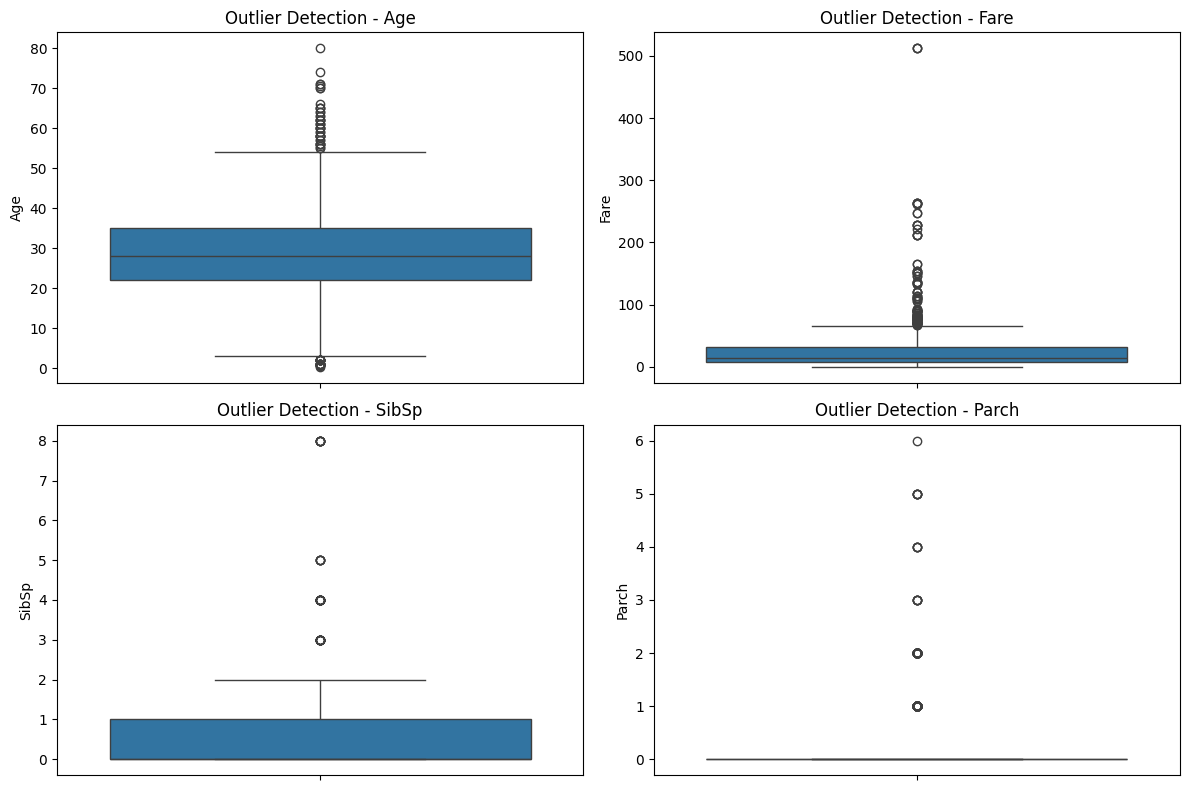

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = ['Age', 'Fare', 'SibSp', 'Parch']

plt.figure(figsize=(12, 8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f'Outlier Detection - {col}')

plt.tight_layout()
plt.show()

In [12]:
# Check current data types
print("Before correction:")
print(df.dtypes)

# Ensure numeric columns have correct data types
df['Age'] = pd.to_numeric(df['Age'])
df['Fare'] = pd.to_numeric(df['Fare'])
df['SibSp'] = pd.to_numeric(df['SibSp']).astype(int)
df['Parch'] = pd.to_numeric(df['Parch']).astype(int)

# Standardize text columns
text_columns = ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']

for col in text_columns:
    df[col] = df[col].astype(str).str.strip()

print("\nAfter correction:")
print(df.dtypes)

Before correction:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

After correction:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [13]:
print("========== FINAL DATA QUALITY REPORT ==========")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nMissing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe().T)

========== FINAL DATA QUALITY REPORT ==========
Total Rows: 891
Total Columns: 12

Missing Values: 0
Duplicate Rows: 0

Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,891.0,29.361582,13.019697,0.42,22.0000,28.0000,35.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [15]:
import os

os.makedirs("output", exist_ok=True)

df.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
